# Paper 1: supplemental learning-rate experiment

Ten AlexNet/MLP runs, including clean baselines, start from initialization.
Initial LR=.01, decay=.95 per epoch, minimum LR=.001, maximum 400 epochs.
This is a supplemental protocol, not the original paper schedule.
Original files remain unchanged. Convergence uses measured first-zero events;
missing events remain censored. Relative times use same-protocol clean baselines.
The eight original Inception runs remain in the original notebook.
Actual cell outputs will be produced during execution.


## 1. Environment and configuration (safe defaults)

In [1]:
from __future__ import annotations
%matplotlib inline
import os, sys, json, csv, math, time, random, hashlib, shutil, platform, warnings
from pathlib import Path
from dataclasses import dataclass, asdict, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import CIFAR10

IMPLEMENTATION_VERSION = 'paper1_supplement_lr_floor_001_budget400_v1'

print('Implementation version:', IMPLEMENTATION_VERSION)
print('Python:', sys.version.split()[0], 'PyTorch:', torch.__version__)
print('NumPy:', np.__version__, 'torchvision available; CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
print('OS:', platform.platform())
print('Working directory:', Path.cwd())
print('Free space (GB):', round(shutil.disk_usage(Path.cwd()).free / 1e9, 2))

Implementation version: paper1_supplement_lr_floor_001_budget400_v1
Python: 3.11.15 PyTorch: 2.11.0+cu128
NumPy: 2.4.6 torchvision available; CUDA: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
OS: Linux-6.8.0-138-generic-x86_64-with-glibc2.39
Working directory: /home/NAS/yangc21/cs6362
Free space (GB): 5687.69


In [2]:
@dataclass(frozen=True)
class Config:
    mode: str = 'smoke'              # 'smoke' or 'full'
    seed: int = 0
    batch_size: int = 128
    max_epochs_full: int = 400
    minimum_lr: float = 0.001       # USER-CHOSEN BUDGET, NOT SPECIFIED BY THE PAPER
    max_epochs_smoke: int = 2
    smoke_train_size: int = 256
    smoke_test_size: int = 128
    smoke_scope: str = 'minimal'      # 'minimal' = 8 coverage runs; 'all' = all 18
    train_loss_stop_threshold: float = 0.01  # separate from first-zero convergence definition
    num_workers: int = 0            # safest for notebook and on-disk arrays
    data_root: str = './paper1_data'
    output_root: str = './paper1_outputs_lr_floor'  # NEVER reuse v1 checkpoints
    download: bool = True           # only used after START_TRAINING=True

CFG = replace(Config(), mode='full')
START_TRAINING = True  # CHANGE TO TRUE ONLY AFTER INSPECTING THE CODE

assert CFG.mode in {'smoke', 'full'}
assert CFG.smoke_scope in {'minimal', 'all'}
assert CFG.max_epochs_full > 0 and CFG.max_epochs_smoke > 0
assert CFG.batch_size == 128 and CFG.seed == 0, 'Initial requested setup: batch=128, seed=0'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert Path(CFG.output_root).name == 'paper1_outputs_lr_floor'
print('Mode:', CFG.mode, '| Device:', DEVICE, '| Start training:', START_TRAINING)
print('Max epochs for chosen mode:', CFG.max_epochs_full if CFG.mode == 'full' else CFG.max_epochs_smoke)
assert DEVICE.type == 'cuda', 'Submit through Slurm on a GPU.'


Mode: full | Device: cuda | Start training: True
Max epochs for chosen mode: 400


## 2. Architecture definitions and Figure-3 path audit (v2)

**Small Inception:** Follow the *connecting path* in Figure 3, not the visual top-to-bottom positions alone. After the first `DownsampleModule(80)` use **(112,48) → (96,64) → (80,80) → (48,96)**. Each Conv Module is **conv → BatchNorm → ReLU**, as explicitly depicted. An Inception module concatenates 1×1 and 3×3 branches; a downsample module concatenates stride-2 3×3-convolution and 3×3-max-pool branches. With the **chosen** same padding for 3×3 and padded stride-2 operations, intermediate shapes must be **28×28 → 14×14 → 7×7**. Padding is not specified in the paper.

**Parameter convention, inference rather than authors' explicit statement:** The corrected Inception has **1,644,320 conv weights + 1,712 conv biases + 3,370 fully connected parameters = 1,649,402**, exactly the Table-1 total. The **3,424 BatchNorm trainable affine parameters** raise PyTorch's full trainable count to **1,652,826**. This is consistent with the hypothesis that Table 1 excluded BatchNorm affine parameters, **but the text does not establish how the authors counted parameters**. Do not delete BatchNorm to force a count match. BatchNorm running-mean/variance buffers are not trainable parameters and are not counted in either total.

**Small AlexNet:** Appendix A provides two (5×5 convolution → 3×3 pool → LRN) modules followed by FC(384,192) and 10 logits, but not every conv width/padding/stride. **Chosen**: 64 channels in each conv, padding 2, pool stride 2 and padding 1, PyTorch `LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2)`. Count matches Table 1 but matching a count does not prove all hyperparameters match the original.

**MLP:** Flatten 28×28×3 → 512 ReLU → 10 logits. Exact Table-1 count.


In [3]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, stride: int = 1):
        super().__init__(
            nn.Conv2d(in_ch, out_ch, kernel_size, stride=stride,
                      padding=kernel_size // 2, bias=True),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

class InceptionModule(nn.Module):
    def __init__(self, in_ch: int, channels_1x1: int, channels_3x3: int):
        super().__init__()
        self.path1 = ConvBNReLU(in_ch, channels_1x1, 1)
        self.path3 = ConvBNReLU(in_ch, channels_3x3, 3)
    def forward(self, x):
        return torch.cat((self.path1(x), self.path3(x)), dim=1)

class DownsampleModule(nn.Module):
    def __init__(self, in_ch: int, conv_ch: int):
        super().__init__()
        self.path_conv = ConvBNReLU(in_ch, conv_ch, 3, stride=2)
        self.path_pool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
    def forward(self, x):
        return torch.cat((self.path_conv(x), self.path_pool(x)), dim=1)

class SmallInception(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [ConvBNReLU(3, 96, 3)]
        current = 96
        for a, b in [(32, 32), (32, 48)]:
            layers.append(InceptionModule(current, a, b))
            current = a + b
        layers.append(DownsampleModule(current, 80))
        current += 80
        for a, b in [(112, 48), (96, 64), (80, 80), (48, 96)]:
            layers.append(InceptionModule(current, a, b))
            current = a + b
        layers.append(DownsampleModule(current, 96))
        current += 96
        for a, b in [(176, 160), (176, 160)]:
            layers.append(InceptionModule(current, a, b))
            current = a + b
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(current, 10))
    def forward(self, x):
        return self.head(self.features(x))

class SmallAlexNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2),
            nn.Conv2d(64, 64, kernel_size=5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 384), nn.ReLU(inplace=True),
            nn.Linear(384, 192), nn.ReLU(inplace=True), nn.Linear(192, 10),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

class MLP1x512(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * 28 * 28, 512),
                                 nn.ReLU(inplace=True), nn.Linear(512, 10))
    def forward(self, x):
        return self.net(x)

MODELS = {'inception': SmallInception, 'alexnet': SmallAlexNet, 'mlp1x512': MLP1x512}
INITIAL_LR = {'inception': 0.1, 'alexnet': 0.01, 'mlp1x512': 0.01}
PAPER_COUNTS = {'inception': 1_649_402, 'alexnet': 1_387_786, 'mlp1x512': 1_209_866}

def parameter_count(model):
    return sum(p.numel() for p in model.parameters())

def parameter_breakdown(model):
    conv_weights = sum(layer.weight.numel() for layer in model.modules()
                       if isinstance(layer, nn.Conv2d))
    conv_biases = sum(layer.bias.numel() for layer in model.modules()
                      if isinstance(layer, nn.Conv2d) and layer.bias is not None)
    fc_params = sum(param.numel() for layer in model.modules()
                    if isinstance(layer, nn.Linear) for param in layer.parameters())
    bn_affine = sum(param.numel() for layer in model.modules()
                    if isinstance(layer, nn.modules.batchnorm._BatchNorm)
                    for param in layer.parameters(recurse=False))
    accounted = conv_weights + conv_biases + fc_params + bn_affine
    assert accounted == parameter_count(model), f'Unknown trainable parameter class: {accounted} vs {parameter_count(model)}'
    return {'conv_weights': conv_weights, 'conv_biases': conv_biases,
            'fully_connected': fc_params, 'batchnorm_affine': bn_affine,
            'excluding_batchnorm_affine': conv_weights + conv_biases + fc_params,
            'all_trainable': accounted}

counts = []
for name, cls in MODELS.items():
    model = cls()
    parts = parameter_breakdown(model)
    counts.append({'model': name, **parts,
                   'paper_table1_parameters': PAPER_COUNTS[name],
                   'difference_excluding_bn': parts['excluding_batchnorm_affine'] - PAPER_COUNTS[name],
                   'difference_all_trainable': parts['all_trainable'] - PAPER_COUNTS[name]})
    del model
PARAMETER_COUNTS = pd.DataFrame(counts)
display(PARAMETER_COUNTS)
assert (PARAMETER_COUNTS.difference_excluding_bn == 0).all(), 'The published counts must match after specified exclusion.'
inc = PARAMETER_COUNTS.set_index('model').loc['inception']
assert (int(inc.conv_weights), int(inc.conv_biases), int(inc.fully_connected)) == (1_644_320, 1_712, 3_370)
assert int(inc.batchnorm_affine) == 3_424
assert int(inc.all_trainable) == 1_652_826

@torch.inference_mode()
def check_inception_spatial_dimensions():
    model = SmallInception().eval()
    x = torch.zeros(1, 3, 28, 28)
    expected = [
        (96, 28, 28), (64, 28, 28), (80, 28, 28),
        (160, 14, 14), (160, 14, 14), (160, 14, 14),
        (160, 14, 14), (144, 14, 14), (240, 7, 7),
        (336, 7, 7), (336, 7, 7),
    ]
    observed = []
    for idx, (block, expected_shape) in enumerate(zip(model.features, expected)):
        x = block(x)
        got = tuple(x.shape[1:])
        assert got == expected_shape, f'Inception feature[{idx}]: expected {expected_shape}, got {got}'
        observed.append({'feature_index': idx, 'module': type(block).__name__,
                         'channels': got[0], 'height': got[1], 'width': got[2]})
    assert len(model.features) == len(expected)
    assert model.head(x).shape == (1, 10)
    return pd.DataFrame(observed)

SPATIAL_AUDIT = check_inception_spatial_dimensions()
display(SPATIAL_AUDIT)
print('Inception shapes and both parameter-count conventions verified.')


,model,conv_weights,conv_biases,fully_connected,batchnorm_affine,excluding_batchnorm_affine,all_trainable,paper_table1_parameters,difference_excluding_bn,difference_all_trainable
0,inception,1644320,1712,3370,3424,1649402,1652826,1649402,0,3424
1,alexnet,107200,128,1280458,0,1387786,1387786,1387786,0,0
2,mlp1x512,0,0,1209866,0,1209866,1209866,1209866,0,0


,feature_index,module,channels,height,width
0,0,ConvBNReLU,96,28,28
1,1,InceptionModule,64,28,28
2,2,InceptionModule,80,28,28
3,3,DownsampleModule,160,14,14
4,4,InceptionModule,160,14,14
5,5,InceptionModule,160,14,14
6,6,InceptionModule,160,14,14
7,7,InceptionModule,144,14,14
8,8,DownsampleModule,240,7,7
9,9,InceptionModule,336,7,7


Inception shapes and both parameter-count conventions verified.


## 3. Preprocessing, corruption and fixed input caches

For each image, center crop `[2:30,2:30,:]`, scale by 255, then whiten across all **2,352 scalar values**. Use the population standard deviation, floored at `1/sqrt(2352)`. No train-set-wide channel normalization, random augmentations, or test-time augmentation.

- Image and label randomization is **deterministic and retained across epochs**. Each randomized image is materialized in `.npy` arrays under the mode-specific cache folder. They are not resampled in the `Dataset` or DataLoader.
- For the shared shuffled-pixel condition, **train and test use one identical spatial permutation**. For the independently shuffled condition, each train/test image has its own persistent spatial permutation. All three RGB values at a spatial location move together.
- Gaussian images use *global scalar* training-set mean and population standard deviation after `/255` and center-cropping; Gaussian pixels are not clipped. The same whitening operator is then applied. This convention is not fully specified by the authors.
- Partial corruption uses uniform class replacement; corrupting with probability p means an expected **0.9p** fraction of CIFAR-10 labels differ. The same underlying random uniforms and class candidates are reused over p and architectures; all test labels are untouched.
- Smoke mode takes a deterministic prefix of the standard CIFAR split. It is only a software check; the smaller data size and short budget invalidate quantitative comparisons with Fig. 1.

In [4]:
def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def center_crop_28(images: np.ndarray) -> np.ndarray:
    assert images.ndim == 4 and images.shape[1:] == (32, 32, 3)
    return images[:, 2:30, 2:30, :]

def whiten_28(batch_hwc: torch.Tensor) -> torch.Tensor:
    """Input (B,H,W,C) raw uint8 [0,255] or Gaussian float32 already in [0,1] scale."""
    if batch_hwc.dtype == torch.uint8:
        x = batch_hwc.to(torch.float32) / 255.0
    else:
        x = batch_hwc.to(torch.float32)  # Gaussian is generated on the [0,1] intensity scale
    assert x.ndim == 4 and tuple(x.shape[1:]) == (28, 28, 3)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    std = torch.sqrt(((x - mean) ** 2).mean(dim=(1, 2, 3), keepdim=True))
    std = torch.clamp(std, min=1.0 / math.sqrt(28 * 28 * 3))
    return ((x - mean) / std).permute(0, 3, 1, 2).contiguous()

class PreparedCIFAR(Dataset):
    def __init__(self, data_28_hwc: np.ndarray, labels: np.ndarray):
        assert data_28_hwc.shape[0] == len(labels)
        assert data_28_hwc.shape[1:] == (28, 28, 3)
        self.images = data_28_hwc   # in-memory original array or read-only .npy memmap
        self.labels = np.asarray(labels, dtype=np.int64).copy()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        # Return a raw image. A batch-level collator applies exactly the same
        # independent per-image whitening, without 50k tiny torch operations.
        raw = np.array(self.images[idx], copy=True)
        return torch.from_numpy(raw), int(self.labels[idx])

def collate_and_whiten(batch):
    images = torch.stack([image for image, _ in batch], dim=0)
    labels = torch.tensor([label for _, label in batch], dtype=torch.long)
    return whiten_28(images), labels

def load_cifar_splits(cfg: Config):
    """Only called from the explicit training entry point, never during notebook import."""
    root = Path(cfg.data_root).resolve()
    train = CIFAR10(root=str(root), train=True, download=cfg.download)
    test = CIFAR10(root=str(root), train=False, download=cfg.download)
    assert len(train) == 50_000 and len(test) == 10_000
    n_tr = len(train) if cfg.mode == 'full' else min(cfg.smoke_train_size, len(train))
    n_te = len(test) if cfg.mode == 'full' else min(cfg.smoke_test_size, len(test))
    train_img = np.ascontiguousarray(center_crop_28(train.data[:n_tr]))
    test_img = np.ascontiguousarray(center_crop_28(test.data[:n_te]))
    y_train = np.asarray(train.targets[:n_tr], dtype=np.int64)
    y_test = np.asarray(test.targets[:n_te], dtype=np.int64)
    return train_img, y_train, test_img, y_test

def label_grid(y_train: np.ndarray, seed: int):
    rng = np.random.default_rng(seed + 17_001)
    uniforms = rng.random(len(y_train))
    replacement = rng.integers(0, 10, size=len(y_train), dtype=np.int64)
    def corrupt(p):
        return np.where(uniforms < float(p), replacement, y_train).astype(np.int64)
    return corrupt

def array_content_signature(arr: np.ndarray):
    a = np.asarray(arr)
    return hashlib.sha256(a.tobytes()).hexdigest()[:16]

def _save_npy_atomically(destination: Path, arr: np.ndarray):
    tmp = destination.with_name(destination.name + '.partial.npy')
    np.save(tmp, arr)
    os.replace(tmp, destination)

def materialize_input_variants(train_original, test_original, cfg, variant):
    """Cache fixed 28x28x3 arrays. Original data is not unnecessarily copied to disk."""
    assert variant in {'original', 'shuffled_pixels', 'random_pixels', 'gaussian'}
    if variant == 'original':
        return train_original, test_original
    directory = Path(cfg.output_root) / cfg.mode / 'input_cache'
    directory.mkdir(parents=True, exist_ok=True)
    stem = f'{variant}_seed{cfg.seed}_n{len(train_original)}_{len(test_original)}'
    paths = [directory / f'{stem}_{split}.npy' for split in ('train', 'test')]
    manifest_path = directory / f'{stem}.json'
    spec = {'variant': variant, 'seed': cfg.seed, 'implementation_version': IMPLEMENTATION_VERSION,
            'shape_train': list(train_original.shape),
            'shape_test': list(test_original.shape),
            'train_original_hash': array_content_signature(train_original),
            'test_original_hash': array_content_signature(test_original),
            'convention': 'RGB triplets spatially permuted; global Gaussian scalar moments'}
    if all(p.exists() for p in paths) and manifest_path.exists():
        if json.loads(manifest_path.read_text()) == spec:
            return tuple(np.load(p, mmap_mode='r') for p in paths)
        raise RuntimeError('Existing input-cache manifest is incompatible. Inspect before deleting cache.')

    rng_train = np.random.default_rng(cfg.seed + {'shuffled_pixels': 22_001,
                                                   'random_pixels': 23_001,
                                                   'gaussian': 24_001}[variant])
    rng_test = np.random.default_rng(cfg.seed + {'shuffled_pixels': 22_002,
                                                  'random_pixels': 23_002,
                                                  'gaussian': 24_002}[variant])
    shared_permutation = rng_train.permutation(28*28) if variant == 'shuffled_pixels' else None
    if variant == 'gaussian':
        z = train_original.astype(np.float64) / 255.0
        mu, sigma = float(z.mean()), float(z.std(ddof=0))
        print('Gaussian moments from center-cropped TRAIN pixels:', mu, sigma)
        dtype = np.float32
    else:
        dtype = np.uint8

    for src, rng, path in zip((train_original, test_original), (rng_train, rng_test), paths):
        tmp = path.with_name(path.name + '.partial.npy')
        mm = np.lib.format.open_memmap(tmp, mode='w+', dtype=dtype, shape=src.shape)
        for i in range(len(src)):
            if variant == 'gaussian':
                mm[i] = rng.normal(mu, sigma, size=(28,28,3)).astype(np.float32)
            else:
                permutation = shared_permutation if shared_permutation is not None else rng.permutation(784)
                mm[i] = src[i].reshape(784, 3)[permutation].reshape(28,28,3)
        mm.flush()
        del mm
        os.replace(tmp, path)
    manifest_path.write_text(json.dumps(spec, indent=2))
    return tuple(np.load(p, mmap_mode='r') for p in paths)

## 4. Run manifest: exactly 18 unique experiments

The two original-input Inception cases `p=0` and `p=1` are shared between Fig. 1(a) and panels (b,c), **not retrained**. The other three Fig. 1(a) input conditions are Inception with true labels. In full mode, the remaining experiments cover all five corruption probabilities and all three architectures.

`smoke_scope='minimal'` selects five representative runs from the same manifest to check architectures, label handling and transformed inputs. `smoke_scope='all'` checks the full 18-run pipeline using smoke-sized data. Neither is a scientific reproduction.

In [5]:
CORRUPTION_PS = (0.0, 0.25, 0.5, 0.75, 1.0)

def run_id(model, variant, p):
    # Explicit stable float encoding; no Python built-in hash() used.
    return f'{model}__{variant}__p{int(round(p*100)):03d}'

def full_run_manifest():
    rows = []
    for model in MODELS:
        for p in CORRUPTION_PS:
            rows.append({'run_id': run_id(model, 'original', p),
                         'model': model, 'variant': 'original', 'p': p,
                         'panel_a': model == 'inception' and p in (0.0, 1.0),
                         'panel_bc': True})
    for variant in ('shuffled_pixels', 'random_pixels', 'gaussian'):
        rows.append({'run_id': run_id('inception', variant, 0.0),
                     'model': 'inception', 'variant': variant, 'p': 0.0,
                     'panel_a': True, 'panel_bc': False})
    assert len(rows) == 18 and len({r['run_id'] for r in rows}) == 18
    assert sum(r['panel_a'] for r in rows) == 5
    assert sum(r['panel_bc'] for r in rows) == 15
    return rows

def selected_manifest(cfg):
    rows = full_run_manifest()
    if cfg.mode == 'full':
        rows = [r for r in rows if r['model'] in {'alexnet', 'mlp1x512'}]
        assert len(rows) == 10
    if cfg.mode == 'smoke' and cfg.smoke_scope == 'minimal':
        # Coverage-first lightweight smoke: Fig. 1(a)'s five treatments,
        # the intermediate p=0.5 label treatment, and ALL THREE models.
        wanted = {
            run_id('inception', 'original', 0),
            run_id('inception', 'original', 1),
            run_id('inception', 'original', 0.5),
            run_id('inception', 'shuffled_pixels', 0),
            run_id('inception', 'random_pixels', 0),
            run_id('inception', 'gaussian', 0),
            run_id('alexnet', 'original', 0.5),
            run_id('mlp1x512', 'original', 0.5),
        }
        rows = [r for r in rows if r['run_id'] in wanted]
    if cfg.mode == 'smoke':
        assert set(r['model'] for r in rows) == set(MODELS)
        assert {'original', 'shuffled_pixels', 'random_pixels', 'gaussian'} <= set(r['variant'] for r in rows)
        assert len([r for r in rows if r['model'] == 'inception' and r['panel_a']]) == 5
        assert any(r['p'] not in (0.0, 1.0) for r in rows), 'Exercise partial label corruption'
    return rows

manifest_df = pd.DataFrame(selected_manifest(CFG))
display(manifest_df)
print('Selected for current mode:', len(selected_manifest(CFG)))

,run_id,model,variant,p,panel_a,panel_bc
0,alexnet__original__p000,alexnet,original,0.00,False,True
1,alexnet__original__p025,alexnet,original,0.25,False,True
2,alexnet__original__p050,alexnet,original,0.50,False,True
3,alexnet__original__p075,alexnet,original,0.75,False,True
4,alexnet__original__p100,alexnet,original,1.00,False,True
5,mlp1x512__original__p000,mlp1x512,original,0.00,False,True
6,mlp1x512__original__p025,mlp1x512,original,0.25,False,True
7,mlp1x512__original__p050,mlp1x512,original,0.50,False,True
8,mlp1x512__original__p075,mlp1x512,original,0.75,False,True
9,mlp1x512__original__p100,mlp1x512,original,1.00,False,True


Selected for current mode: 10


## 5. Training, checkpointing, complete-set evaluation, and raw metric export (v2)

At every epoch boundary evaluate **every** example in the relevant training and test split. At the **first observed zero training misclassification**, atomically write `first_zero.pt` *before* updating `last.pt`. This artifact captures epoch, optimizer step, model state, optimizer/scheduler state, and the **same-epoch test loss/error/accuracy**. Never overwrite it during subsequent epochs; later epochs update only `last.pt` and metric CSVs. On resume, cross-check signature and first-zero metadata. First ≥99.9% training accuracy is recorded independently. An unobserved threshold is censored, not imputed.

Versioned outputs (`paper1_outputs_v2/smoke` vs `paper1_outputs_v2/full`) prevent both v1 checkpoint reuse and mixing of smoke and reproduction results.

In [6]:
@torch.inference_mode()
def evaluate_entire_dataset(model, dataset, batch_size, device, num_workers=0):
    """Exhaustively evaluate original full train/test subset, never just the last mini-batch."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=(device.type == 'cuda'),
                        collate_fn=collate_and_whiten)
    model.eval()
    total_loss_sum, total_wrong, total_n = 0.0, 0, 0
    loss_fn = nn.CrossEntropyLoss(reduction='sum')
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        total_loss_sum += float(loss_fn(logits, y).item())
        total_wrong += int((logits.argmax(dim=1) != y).sum().item())
        total_n += y.numel()
    assert total_n == len(dataset)
    return {'loss': total_loss_sum / total_n,
            'wrong': total_wrong, 'accuracy': 1.0 - total_wrong / total_n,
            'error': total_wrong / total_n, 'n': total_n}

def atomic_csv(destination: Path, records):
    tmp = destination.with_name(destination.name + '.partial.csv')
    pd.DataFrame.from_records(records).to_csv(tmp, index=False)
    os.replace(tmp, destination)

def atomic_checkpoint(destination: Path, payload):
    tmp = destination.with_name(destination.name + '.partial.pt')
    torch.save(payload, tmp)
    os.replace(tmp, destination)

def save_first_zero_once(first_zero_path: Path, signature: str, row: dict, state: dict):
    """Persist first observed full-set zero error; never overwrite an existing snapshot.

    Existing snapshots are checked on restart, including after an interruption
    between writing first_zero.pt and last.pt. This helper is independently
    smoke-tested using synthetic payloads, without running optimization.
    """
    assert bool(row['reached_zero_at_checkpoint']) and int(row['train_wrong']) == 0
    assert state['epoch'] == row['epoch'] and state['steps'] == row['optimizer_step']
    if first_zero_path.exists():
        prior = torch.load(first_zero_path, map_location='cpu', weights_only=False)
        prior_row = prior.get('first_zero_metrics', {})
        if (prior.get('signature') != signature or
            prior.get('artifact_type') != 'first_zero' or
            prior.get('implementation_version') != IMPLEMENTATION_VERSION or
            prior.get('epoch') != row['epoch'] or
            prior.get('steps') != row['optimizer_step'] or
            any(prior_row.get(k) != row[k] for k in
                ('train_wrong', 'train_loss', 'test_loss', 'test_error', 'test_accuracy'))):
            raise RuntimeError(f'Incompatible first-zero artifact at {first_zero_path}; preserve and inspect it.')
        return False  # same first-zero observation, e.g. recovery after interruption
    snapshot = dict(state)
    snapshot['artifact_type'] = 'first_zero'
    snapshot['implementation_version'] = IMPLEMENTATION_VERSION
    snapshot['first_zero_metrics'] = dict(row)
    atomic_checkpoint(first_zero_path, snapshot)
    return True

def run_signature(cfg, spec, train_images, y_train, test_images, y_test):
    material = {'spec': spec, 'seed': cfg.seed, 'batch_size': cfg.batch_size,
                'mode': cfg.mode, 'max_epochs': cfg.max_epochs_full if cfg.mode == 'full' else cfg.max_epochs_smoke,
                'train_loss_stop_threshold': cfg.train_loss_stop_threshold,
                'minimum_lr': cfg.minimum_lr,
                'scheduler_protocol': 'exponential_095_with_floor',
                'train_image_hash': array_content_signature(train_images),
                'train_label_hash': array_content_signature(y_train),
                'test_image_hash': array_content_signature(test_images),
                'test_label_hash': array_content_signature(y_test),
                'source_version': IMPLEMENTATION_VERSION}
    signature = hashlib.sha256(json.dumps(material, sort_keys=True).encode()).hexdigest()
    return signature, material

def train_one_run(cfg, spec, train_images, corrupted_train_labels, test_images, true_test_labels):
    run_root = Path(cfg.output_root) / cfg.mode / 'runs' / spec['run_id']
    run_root.mkdir(parents=True, exist_ok=True)
    ckpt_path = run_root / 'last.pt'
    first_zero_path = run_root / 'first_zero.pt'
    history_path = run_root / 'epoch_metrics.csv'
    summary_path = run_root / 'summary.json'
    signature, signature_material = run_signature(cfg, spec, train_images, corrupted_train_labels,
                                                  test_images, true_test_labels)

    # Same model seed for different p and input corruption conditions.
    arch_seed = cfg.seed + {'inception': 101, 'alexnet': 102, 'mlp1x512': 103}[spec['model']]
    set_all_seeds(arch_seed)
    model = MODELS[spec['model']]().to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=INITIAL_LR[spec['model']],
                                momentum=0.9, weight_decay=0.0)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lr_lambda=lambda k: max(
            0.95 ** k, cfg.minimum_lr / INITIAL_LR[spec['model']]))
    train_set = PreparedCIFAR(train_images, corrupted_train_labels)
    test_set = PreparedCIFAR(test_images, true_test_labels)
    criterion = nn.CrossEntropyLoss()

    start_epoch, step, records = 0, 0, []
    if ckpt_path.exists():
        # Only load locally created checkpoints from this trusted notebook.
        state = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        if state['signature'] != signature:
            raise RuntimeError(f'Incompatible checkpoint for {spec["run_id"]}. Do not silently overwrite it.')
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        start_epoch, step, records = int(state['epoch']), int(state['steps']), list(state['records'])
        torch.set_rng_state(state['torch_rng'].cpu())
        if DEVICE.type == 'cuda' and state['cuda_rng'] is not None:
            torch.cuda.set_rng_state_all([x.cpu() for x in state['cuda_rng']])
        atomic_csv(history_path, records)  # heals interruption after checkpoint write
        print(f'RESUME {spec["run_id"]}: completed epoch={start_epoch}, steps={step}')

    if first_zero_path.exists():
        # Avoid silently trusting an artifact from a different implementation/run.
        prior_first = torch.load(first_zero_path, map_location='cpu', weights_only=False)
        if (prior_first.get('signature') != signature or
            prior_first.get('implementation_version') != IMPLEMENTATION_VERSION or
            prior_first.get('artifact_type') != 'first_zero'):
            raise RuntimeError(f'Incompatible first_zero.pt found for {spec["run_id"]}.')

    max_epochs = cfg.max_epochs_full if cfg.mode == 'full' else cfg.max_epochs_smoke
    if records and records[-1]['stop_condition_met']:
        print('Already complete:', spec['run_id'])
    for epoch in range(start_epoch + 1, max_epochs + 1):
        if records and records[-1]['stop_condition_met']:
            break
        model.train()
        loader_generator = torch.Generator().manual_seed(
            arch_seed + 100_003 * epoch + 17)
        loader = DataLoader(train_set, batch_size=cfg.batch_size, shuffle=True,
                            generator=loader_generator, num_workers=cfg.num_workers,
                            pin_memory=(DEVICE.type == 'cuda'),
                            collate_fn=collate_and_whiten)
        # Sum the actual minibatch losses for diagnostics; the figure uses full-set eval loss below.
        weighted_train_step_loss, epoch_samples = 0.0, 0
        epoch_t0 = time.perf_counter()
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            step += 1
            weighted_train_step_loss += float(loss.item()) * len(y)
            epoch_samples += len(y)
        assert epoch_samples == len(train_set)
        # The optimizer performed this epoch with the pre-scheduler LR.
        lr_this_epoch = float(optimizer.param_groups[0]['lr'])
        scheduler.step()  # decay 0.95 after *each* completed epoch, never per step

        # Important: full-set, deterministic evaluation at epoch boundary.
        train_eval = evaluate_entire_dataset(model, train_set, cfg.batch_size, DEVICE, cfg.num_workers)
        test_eval = evaluate_entire_dataset(model, test_set, cfg.batch_size, DEVICE, cfg.num_workers)
        wrong_999_limit = math.floor(0.001 * len(train_set) + 1e-9)
        reached_999 = train_eval['wrong'] <= wrong_999_limit
        reached_zero = train_eval['wrong'] == 0
        stop_condition_met = bool(reached_zero and train_eval['loss'] <= cfg.train_loss_stop_threshold)
        row = {'run_id': spec['run_id'], 'model': spec['model'], 'variant': spec['variant'],
               'p': float(spec['p']), 'mode': cfg.mode, 'seed': cfg.seed,
               'epoch': epoch, 'optimizer_step': step,
               'lr_used': lr_this_epoch, 'train_examples': len(train_set),
               'test_examples': len(test_set), 'train_loss': train_eval['loss'],
               'train_error': train_eval['error'], 'train_wrong': train_eval['wrong'],
               'train_accuracy': train_eval['accuracy'], 'test_loss': test_eval['loss'],
               'test_error': test_eval['error'], 'test_accuracy': test_eval['accuracy'],
               'mini_batch_train_loss': weighted_train_step_loss / epoch_samples,
               'reached_zero_at_checkpoint': reached_zero,
               'reached_999_at_checkpoint': reached_999,
               'stop_condition_met': stop_condition_met,
               'epoch_wall_seconds': time.perf_counter() - epoch_t0}
        records.append(row)

        state = {'signature': signature, 'signature_material': signature_material,
                 'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                 'scheduler': scheduler.state_dict(), 'epoch': epoch, 'steps': step,
                 'torch_rng': torch.get_rng_state(),
                 'cuda_rng': torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None,
                 'records': records}
        # Save first-zero model weights and exact corresponding metrics even if
        # this run will continue in subsequent epochs to decrease cross-entropy.
        is_first_zero = reached_zero and not any(r['reached_zero_at_checkpoint'] for r in records[:-1])
        if is_first_zero:
            created = save_first_zero_once(first_zero_path, signature, row, state)
            if created:
                print(f'FIRST ZERO SNAPSHOT: {first_zero_path} epoch={epoch} step={step} '
                      f'test_error={test_eval["error"]:.6f}')
        atomic_checkpoint(ckpt_path, state)   # checkpoint BEFORE writing metrics
        atomic_csv(history_path, records)      # rerun restores metrics from checkpoint if needed
        print(f"{spec['run_id']} epoch={epoch}/{max_epochs} step={step} "
              f"train_wrong={train_eval['wrong']} CE={train_eval['loss']:.4f} "
              f"test_error={test_eval['error']:.3f}")
        if stop_condition_met:
            break

    # Derive first observed checkpoint events from entire recorded history, never the last minibatch.
    hit_zero = next((r for r in records if r['reached_zero_at_checkpoint']), None)
    hit_999 = next((r for r in records if r['reached_999_at_checkpoint']), None)
    last = records[-1] if records else None
    status = 'converged' if hit_zero is not None else 'censored'
    if hit_zero is not None:
        if not first_zero_path.exists():
            raise RuntimeError('Missing first_zero.pt for an observed zero-error checkpoint; cannot silently use last.pt.')
        first_state = torch.load(first_zero_path, map_location='cpu', weights_only=False)
        event = first_state['first_zero_metrics']
        if (first_state['signature'] != signature or first_state['epoch'] != hit_zero['epoch'] or
            first_state['steps'] != hit_zero['optimizer_step'] or
            event['test_error'] != hit_zero['test_error'] or
            event['test_loss'] != hit_zero['test_loss']):
            raise RuntimeError('first_zero.pt disagrees with the recorded epoch metrics.')
    elif first_zero_path.exists():
        # Could indicate interruption after first_zero.pt but before last.pt.
        # Never classify the recovered run as censored in this inconsistent state.
        raise RuntimeError('first_zero.pt exists but last.pt has no matching first-zero record.')
    summary = dict(spec, mode=cfg.mode, seed=cfg.seed, signature=signature,
                   measured_parameter_count=parameter_count(model),
                   max_epochs_budget=max_epochs, completed_epochs=(last['epoch'] if last else 0),
                   completed_steps=(last['optimizer_step'] if last else 0),
                   convergence_status=status,
                   first_zero_epoch=(hit_zero['epoch'] if hit_zero else None),
                   first_zero_step=(hit_zero['optimizer_step'] if hit_zero else None),
                   first_zero_checkpoint=(str(first_zero_path.resolve()) if hit_zero else None),
                   train_loss_at_first_zero=(hit_zero['train_loss'] if hit_zero else None),
                   train_accuracy_at_first_zero=(hit_zero['train_accuracy'] if hit_zero else None),
                   test_loss_at_first_zero=(hit_zero['test_loss'] if hit_zero else None),
                   test_error_at_first_zero=(hit_zero['test_error'] if hit_zero else None),
                   test_accuracy_at_first_zero=(hit_zero['test_accuracy'] if hit_zero else None),
                   first_999_epoch=(hit_999['epoch'] if hit_999 else None),
                   first_999_step=(hit_999['optimizer_step'] if hit_999 else None),
                   final_train_error=(last['train_error'] if last else None),
                   final_train_loss=(last['train_loss'] if last else None),
                   endpoint_test_error_diagnostic=(last['test_error'] if last else None),
                   ended_for_low_loss=bool(last and last['stop_condition_met']),
                   stopped_due_to_budget=bool(last and (last['epoch'] == max_epochs)
                                              and not last['stop_condition_met']))
    tmp = summary_path.with_suffix('.partial.json')
    tmp.write_text(json.dumps(summary, indent=2))
    os.replace(tmp, summary_path)
    return summary

## 6. Aggregation and empirical figure generation

The plotting functions **never train or synthesize values**. Data is read exclusively from saved epoch metrics and run summaries.

- Panel (a) uses `train_loss` measured on the entire training set at each epoch boundary and plots its corresponding optimizer steps.
- Panel (b) uses `first_zero_step(p) / first_zero_step(p=0)` only when **both** are observed; missing convergence points remain missing. The 99.9% sensitivity analysis is exported separately.
- Panel (c) plots the test error from that exact first-zero-error checkpoint, not the test accuracy of a best checkpoint or a censored run.
- A `censored` row means first-zero time was not observed under the epoch budget; it is **not** assigned budget time as a numerical estimate. For Fig. 1c, censored runs do not satisfy the paper's 'after convergence' comparison and are excluded from that panel.

In [7]:
def collect_results(cfg):
    mode_dir = Path(cfg.output_root) / cfg.mode
    summaries, epochs = [], []
    for spec in full_run_manifest():
        root = mode_dir / 'runs' / spec['run_id']
        summary_file = root / 'summary.json'
        epoch_file = root / 'epoch_metrics.csv'
        if summary_file.exists():
            summaries.append(json.loads(summary_file.read_text()))
        if epoch_file.exists():
            df = pd.read_csv(epoch_file)
            if len(df):
                epochs.append(df)
    summary_df = pd.DataFrame(summaries)
    epoch_df = pd.concat(epochs, ignore_index=True) if epochs else pd.DataFrame()
    return summary_df, epoch_df

def convergence_ratio_table(summary_df):
    if summary_df.empty:
        return pd.DataFrame()
    rows = []
    for _, row in summary_df.loc[summary_df.panel_bc == True].iterrows():
        base = summary_df[(summary_df.model == row['model']) &
                          (summary_df.variant == 'original') & (summary_df.p == 0.0)]
        base_step = base.iloc[0]['first_zero_step'] if len(base) else None
        step = row['first_zero_step']
        has_both = pd.notna(base_step) and pd.notna(step) and float(base_step) > 0
        ratio = float(step) / float(base_step) if has_both else np.nan
        rows.append({'run_id': row['run_id'], 'model': row['model'], 'p': row['p'],
                     'convergence_status': row['convergence_status'],
                     'first_zero_step': step,
                     'baseline_first_zero_step': base_step,
                     'relative_convergence_time': ratio,
                     'test_error_at_first_zero': row['test_error_at_first_zero'],
                     'first_999_step': row['first_999_step'],
                     'eligible_for_b': bool(has_both),
                     'eligible_for_c': pd.notna(row['test_error_at_first_zero'])})
    return pd.DataFrame(rows).sort_values(['model', 'p']).reset_index(drop=True)

def export_all_metrics(cfg):
    summaries, epoch_logs = collect_results(cfg)
    out_dir = Path(cfg.output_root) / cfg.mode
    if summaries.empty:
        print('No training artifacts found yet. Nothing to export or plot.')
        return summaries, epoch_logs, pd.DataFrame()
    out_dir.mkdir(parents=True, exist_ok=True)
    summary_file = out_dir / 'all_run_summaries.csv'
    epoch_file = out_dir / 'all_epoch_metrics.csv'
    ratio_file = out_dir / 'fig1bc_measured_only.csv'
    ratios = convergence_ratio_table(summaries)
    summaries.to_csv(summary_file, index=False)
    if not epoch_logs.empty:
        epoch_logs.to_csv(epoch_file, index=False)
    if not ratios.empty:
        ratios.to_csv(ratio_file, index=False)
    PARAMETER_COUNTS.to_csv(out_dir / 'parameter_count_audit.csv', index=False)
    print('Exported raw measured metrics under', out_dir.resolve())
    return summaries, epoch_logs, ratios

def plot_figure1(cfg, summaries, epoch_logs, ratios):
    if epoch_logs.empty:
        print('No measured epoch data available for plotting.')
        return
    figures = Path(cfg.output_root) / cfg.mode / 'figures'
    figures.mkdir(parents=True, exist_ok=True)
    if ratios.empty:
        print('No Fig. 1(b,c) measured metrics yet.')
        return
    for col, ylabel, title, filename in [
        ('relative_convergence_time', 'Relative time to first zero training error',
         'Supplemental convergence slowdown', 'figure1b_convergence.png'),
        ('test_error_at_first_zero', 'Test classification error',
         'Supplemental test error', 'figure1c_test_error.png'),
    ]:
        fig, ax = plt.subplots(figsize=(7, 4.5))
        for model in ('inception', 'alexnet', 'mlp1x512'):
            # Retain NaN at censored corruption probabilities so Matplotlib
            # leaves visible gaps instead of falsely connecting across missing runs.
            subset = ratios[ratios.model == model].sort_values('p')
            if not subset.empty and subset[col].notna().any():
                ax.plot(subset.p, subset[col], marker='o', label=model)
        ax.set(xlabel='Training-label corruption probability p', ylabel=ylabel,
               xlim=(-0.025, 1.025), title=f'{title}, {cfg.mode} (measured; missing=censored)')
        if col == 'test_error_at_first_zero':
            ax.set_ylim(0, 1)
        ax.legend(fontsize=8) if ax.lines else None
        fig.tight_layout()
        fig.savefig(figures / filename, dpi=180)
        plt.show(); plt.close(fig)

## 7. Non-training sanity checks (expanded v2)

**Safe to run immediately:** No CIFAR-10 download, SGD updates or training. Synthetic checks process **all five Figure-1(a) settings** (true labels, fixed random labels, common pixel permutation, independent per-image permutations, Gaussian inputs), each through **all three architectures**. Check the configured 8-run minimal smoke manifest covers all five Figure-1(a) conditions, a partial label-corruption probability and the three models. Inspect input-cache repeatability, Gaussian finiteness, spatial shapes, and a synthetic `first_zero.pt` write/read/idempotency test. Real smoke training remains explicitly guarded in §8.

In [8]:
def sanity_checks():
    from tempfile import TemporaryDirectory

    # Fixed corrupted labels; corruption p can preserve true labels by chance.
    labels = np.arange(1000, dtype=np.int64) % 10
    transform = label_grid(labels, seed=0)
    assert np.array_equal(transform(0.0), labels)
    assert np.array_equal(transform(1.0), transform(1.0))
    assert (transform(1.0) != labels).mean() > 0.85
    assert len(full_run_manifest()) == 18
    assert sum(x['panel_a'] for x in full_run_manifest()) == 5
    assert sum(x['panel_bc'] for x in full_run_manifest()) == 15
    assert CFG.max_epochs_full == 400 and CFG.max_epochs_smoke == 2
    assert CFG.smoke_train_size == 256 and CFG.smoke_test_size == 128

    smoke_spec = selected_manifest(replace(CFG, mode='smoke', smoke_scope='minimal'))
    assert len(smoke_spec) == 8
    assert {s['model'] for s in smoke_spec} == set(MODELS)
    assert len([s for s in smoke_spec if s['panel_a']]) == 5
    assert any(s['p'] == 0.5 for s in smoke_spec)

    # These tiny, deterministic synthetic arrays are NOT CIFAR-10 and are never trained on.
    rng = np.random.default_rng(0)
    original_train = rng.integers(0, 256, (4,28,28,3), dtype=np.uint8)
    original_test = rng.integers(0, 256, (2,28,28,3), dtype=np.uint8)
    with TemporaryDirectory(prefix='paper1_v2_synthetic_only_') as root:
        sanity_cfg = replace(CFG, mode='smoke', output_root=root)
        inputs = {'true labels': original_train, 'random labels': original_train}
        for variant in ('shuffled_pixels', 'random_pixels', 'gaussian'):
            x_train, x_test = materialize_input_variants(original_train, original_test,
                                                         sanity_cfg, variant)
            x_train_again, x_test_again = materialize_input_variants(original_train, original_test,
                                                                     sanity_cfg, variant)
            assert np.array_equal(x_train, x_train_again)
            assert np.array_equal(x_test, x_test_again)
            assert x_train.shape == original_train.shape and x_test.shape == original_test.shape
            if variant == 'gaussian':
                assert np.issubdtype(x_train.dtype, np.floating) and np.isfinite(x_train).all()
            else:
                assert x_train.dtype == np.uint8
                # Spatial RGB-triplet permutation preserves multiset of pixels in each image.
                for i in range(len(x_train)):
                    assert np.array_equal(np.sort(x_train[i].reshape(-1,3), axis=0),
                                          np.sort(original_train[i].reshape(-1,3), axis=0))
            inputs[variant] = np.array(x_train, copy=True)

        assert set(inputs) == {'true labels', 'random labels', 'shuffled_pixels',
                               'random_pixels', 'gaussian'}
        print('Synthetic input conditions:', ', '.join(inputs))
        # Explicitly test every condition with every architecture: 5 × 3 forwards.
        for name, cls in MODELS.items():
            model = cls().eval()
            for condition, x in inputs.items():
                t = whiten_28(torch.from_numpy(x[:1].copy()))
                assert t.shape == (1,3,28,28) and torch.isfinite(t).all()
                assert float(t.mean().abs()) < 1e-4
                with torch.inference_mode():
                    logits = model(t)
                assert logits.shape == (1,10) and torch.isfinite(logits).all(), (name, condition)
            print(f'{name}: 5/5 input conditions forwarded; count={parameter_count(model):,}')
            del model

        # Unit test first_zero.pt without optimizer steps or CIFAR-10 training.
        row = {'epoch': 3, 'optimizer_step': 9, 'train_wrong': 0,
               'reached_zero_at_checkpoint': True, 'train_loss': 0.42,
               'test_loss': 1.35, 'test_error': 0.25, 'test_accuracy': 0.75}
        state = {'signature': 'synthetic_check_only', 'epoch': 3, 'steps': 9,
                 'model': {'fake_weight': torch.tensor([1.0])}}
        path = Path(root) / 'first_zero.pt'
        assert save_first_zero_once(path, 'synthetic_check_only', row, state)
        assert not save_first_zero_once(path, 'synthetic_check_only', row, state)
        snap = torch.load(path, map_location='cpu', weights_only=False)
        assert snap['epoch'] == 3 and snap['steps'] == 9
        assert snap['first_zero_metrics']['test_error'] == 0.25
        assert snap['first_zero_metrics']['test_accuracy'] == 0.75

    assert int(PARAMETER_COUNTS.set_index('model').loc['inception', 'all_trainable']) == 1_652_826
    assert len(SPATIAL_AUDIT) == 11
    print('PASS: 5 conditions × 3 models, 8-run smoke manifest, spatial/count audit, '
          'cached inputs, and first_zero.pt persistence. NO DATA DOWNLOAD / TRAINING.')

sanity_checks()


Gaussian moments from center-cropped TRAIN pixels: 0.5006540116046418 0.29127528216734383
Synthetic input conditions: true labels, random labels, shuffled_pixels, random_pixels, gaussian


inception: 5/5 input conditions forwarded; count=1,652,826
alexnet: 5/5 input conditions forwarded; count=1,387,786
mlp1x512: 5/5 input conditions forwarded; count=1,209,866
PASS: 5 conditions × 3 models, 8-run smoke manifest, spatial/count audit, cached inputs, and first_zero.pt persistence. NO DATA DOWNLOAD / TRAINING.


## 8. Execute the ten supplemental GPU training runs

In [9]:
def execute_experiments(cfg: Config):
    selected = selected_manifest(cfg)
    train_original, y_train, test_original, y_test = load_cifar_splits(cfg)
    corrupt = label_grid(y_train, seed=cfg.seed)
    cache = {'original': (train_original, test_original)}
    all_summaries = []
    for i, spec in enumerate(selected, 1):
        print(f'\n=== {i}/{len(selected)} {spec["run_id"]} ===')
        variant = spec['variant']
        if variant not in cache:
            cache[variant] = materialize_input_variants(train_original, test_original, cfg, variant)
        x_train, x_test = cache[variant]
        labels = corrupt(spec['p']) if variant == 'original' else y_train.copy()
        summary = train_one_run(cfg, spec, x_train, labels, x_test, y_test)
        all_summaries.append(summary)
        # Export after *each* run, so interruptions keep measured progress.
        export_all_metrics(cfg)
    return all_summaries

if START_TRAINING:
    print('EXPLICIT TRAINING ENABLED:', CFG.mode)
    _completed_run_summaries = execute_experiments(CFG)
    print('Finished selected runs:', len(_completed_run_summaries))
else:
    print('Training/download SKIPPED. Inspect code; set START_TRAINING=True when ready.')

EXPLICIT TRAINING ENABLED: full



=== 1/10 alexnet__original__p000 ===


alexnet__original__p000 epoch=1/400 step=391 train_wrong=26812 CE=1.5017 test_error=0.544


alexnet__original__p000 epoch=2/400 step=782 train_wrong=22360 CE=1.2505 test_error=0.456


alexnet__original__p000 epoch=3/400 step=1173 train_wrong=17189 CE=0.9642 test_error=0.366


...

mlp1x512__original__p100 epoch=366/400 step=143106 train_wrong=1 CE=0.0101 test_error=0.905


mlp1x512__original__p100 epoch=367/400 step=143497 train_wrong=1 CE=0.0101 test_error=0.904


mlp1x512__original__p100 epoch=368/400 step=143888 train_wrong=1 CE=0.0100 test_error=0.905


mlp1x512__original__p100 epoch=369/400 step=144279 train_wrong=1 CE=0.0099 test_error=0.905


mlp1x512__original__p100 epoch=370/400 step=144670 train_wrong=0 CE=0.0099 test_error=0.905
Exported raw measured metrics under /home/NAS/yangc21/cs6362/paper1_outputs_lr_floor/full
Finished selected runs: 10


## 9. Produce plots and exports from existing measured runs only

Exported raw measured metrics under /home/NAS/yangc21/cs6362/paper1_outputs_lr_floor/full


,run_id,convergence_status,first_zero_step,first_999_step,test_error_at_first_zero,endpoint_test_error_diagnostic
0,alexnet__original__p000,converged,7820.0,7429,0.2246,0.2246
1,alexnet__original__p025,converged,18768.0,12121,0.4034,0.4034
2,alexnet__original__p050,converged,47311.0,15249,0.5866,0.5866
3,alexnet__original__p075,converged,128248.0,26197,0.7638,0.7638
4,alexnet__original__p100,censored,NaN,49266,NaN,0.9034
5,mlp1x512__original__p000,converged,59823.0,15640,0.4835,0.4833
6,mlp1x512__original__p025,converged,64515.0,34017,0.6067,0.6066
7,mlp1x512__original__p050,converged,59041.0,37145,0.7056,0.7037
8,mlp1x512__original__p075,converged,102833.0,41837,0.8094,0.8089
9,mlp1x512__original__p100,converged,102833.0,43401,0.9046,0.9051


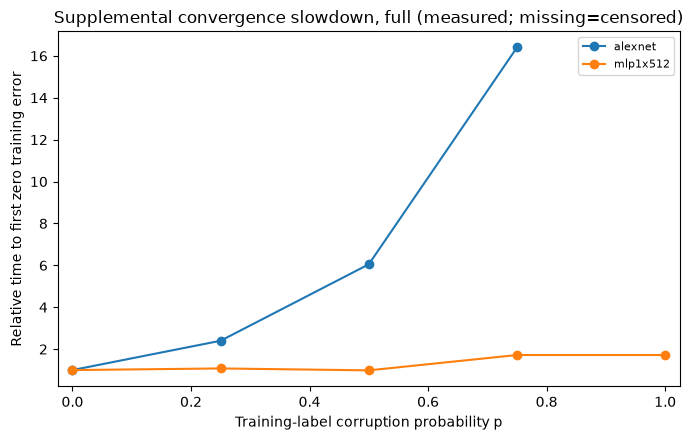

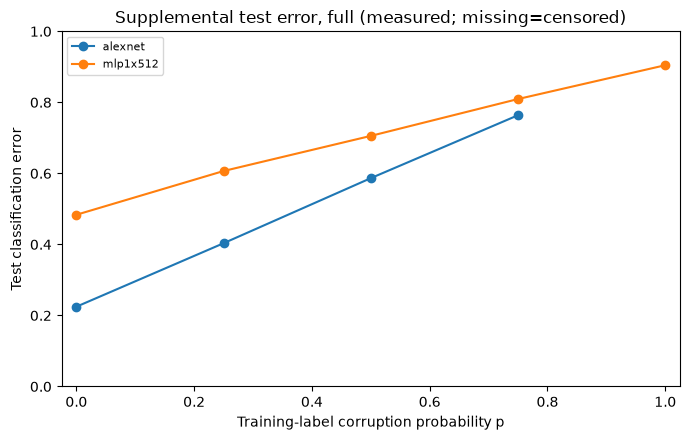

In [10]:
all_summaries_df, all_epochs_df, fig1bc_df = export_all_metrics(CFG)
if not all_summaries_df.empty:
    display(all_summaries_df[['run_id', 'convergence_status', 'first_zero_step',
                              'first_999_step', 'test_error_at_first_zero',
                              'endpoint_test_error_diagnostic']])
    plot_figure1(CFG, all_summaries_df, all_epochs_df, fig1bc_df)
else:
    print('No run artifacts yet. The three plots will be produced after measured runs finish.')

## 10. Report this supplemental protocol separately from the original attempt.